# 🕵️ Le mystère des clients disparus

**Projet de fin de module — Python pour l'analyse des données (sup2tech)** · travail individuel

> ⚠️ *Cas d'étude pédagogique : MarchéPlus est une enseigne **fictive** et les données sont **simulées**.*

### 📧 La demande du directeur commercial (Karim Benali)

Depuis l'été, **le magasin de Rabat va mal** : « les clients fidèles ne viennent plus ». Les autres magasins vont bien.
Avant le comité de fin d'année, il veut savoir :

1. **Est-ce vrai ?** De combien ?
2. **Pourquoi ?**
3. **Qui sont les clients partis, et quand le problème est-il le pire ?**
4. **Combien ça nous coûte ?**
5. **Que faut-il faire, et est-ce rentable ?**

### 🔎 Mes suspects (écrits avant de coder)

| # | Suspect | Comment le tester |
|---|---|---|
| 1 | **L'été** (vacances, départs de la ville) | Les autres magasins baissent-ils aussi en juillet-août ? |
| 2 | **La hausse des prix de mai** | Le panier moyen monte-t-il partout en mai ? La baisse de Rabat commence-t-elle en mai ? |
| 3 | **Des paniers plus petits** (clients qui achètent moins) | CA = nombre de tickets × panier moyen : lequel a bougé ? |
| 4 | **Le temps d'attente en caisse** | Croisement ventes × `attente_caisse.csv` |
| 5 | **Une fermeture du magasin** (travaux, jours fermés) | Nombre de jours d'ouverture par mois |

💡 Taux de marge moyen de MarchéPlus : **21 %**.

### 🧭 Plan
1. Qualité des données · 2. Constat · 3. Cause · 4. Qui est parti ? · 5. Quand ? · 6. Combien ? · 7. Que faire ? · 8. Tableau de bord · 9. Ma question · 10. Conclusions · ⭐ Bonus

## 0. Charger les données et les 4 bibliothèques

| Bibliothèque | Rôle dans le projet |
|---|---|
| **NumPy** `np` | `np.where` (période), `np.select` (segments), `np.corrcoef` (corrélation), `np.polyfit` (simulation) |
| **pandas** `pd` | Lire, contrôler, nettoyer, `pivot_table`, `groupby`, `merge` |
| **Matplotlib** `plt` | Graphiques sur mesure et tableau de bord final |
| **Seaborn** `sns` | `barplot`, `boxplot`, `heatmap`, `regplot` |

On charge les 4 fichiers depuis le dossier `data/`.

▶️ **Sur Google Colab** : exécutez la cellule ci-dessous, cliquez sur **« Choisir les fichiers »** et sélectionnez les **4 CSV** (`tickets.csv`, `clients.csv`, `magasins.csv`, `attente_caisse.csv`). En local (Jupyter), cette cellule ne fait rien.

In [19]:
# Préparation Google Colab : téléverser les 4 CSV dans le dossier data/ (ne fait rien en local)
import os
FICHIERS = ["tickets", "clients", "magasins", "attente_caisse"]
os.makedirs("data", exist_ok=True)
manquants = [f for f in FICHIERS if not os.path.exists(f"data/{f}.csv")]

if manquants:
    try:
        from google.colab import files
        print("Fichiers à téléverser :", ", ".join(f + ".csv" for f in manquants))
        envoyes = files.upload()
        for nom, contenu in envoyes.items():
            # Colab renomme parfois « tickets (1).csv » : on retrouve le bon nom
            cible = next((f for f in FICHIERS if nom.lower().replace(" ", "").startswith(f)), None)
            if cible:
                with open(f"data/{cible}.csv", "wb") as sortie:
                    sortie.write(contenu)
        manquants = [f for f in FICHIERS if not os.path.exists(f"data/{f}.csv")]
        print("✅ Tous les fichiers sont prêts." if not manquants else f"⚠️ Il manque encore : {manquants}")
    except ImportError:
        print("Hors de Colab : placez les 4 CSV dans le dossier data/ à côté du notebook.")
else:
    print("✅ Les 4 fichiers sont déjà dans data/.")

✅ Les 4 fichiers sont déjà dans data/.


In [20]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Réglages d'affichage
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", context="notebook")
ROUGE, GRIS = "#C0392B", "#B0B0B0"          # Rabat en couleur, les autres en gris
MOIS = ["Janv", "Févr", "Mars", "Avr", "Mai", "Juin", "Juil", "Août", "Sept", "Oct"]
JOURS = ["Lun", "Mar", "Mer", "Jeu", "Ven", "Sam", "Dim"]
MARGE = 0.21                                 # taux de marge moyen MarchéPlus

def dh(x):
    # Formate un montant en DH avec un espace comme séparateur de milliers
    return f"{x:,.0f}".replace(",", " ") + " DH"

DATA, IMG = "data/", "images/"
os.makedirs(IMG, exist_ok=True)

tickets  = pd.read_csv(DATA + "tickets.csv")
clients  = pd.read_csv(DATA + "clients.csv")
magasins = pd.read_csv(DATA + "magasins.csv")
attente  = pd.read_csv(DATA + "attente_caisse.csv")

for nom, df in [("tickets", tickets), ("clients", clients), ("magasins", magasins), ("attente", attente)]:
    print(f"{nom:<9}: {df.shape[0]:>6} lignes × {df.shape[1]} colonnes")

tickets  :  33679 lignes × 6 colonnes
clients  :   1762 lignes × 4 colonnes
magasins :      5 lignes × 5 colonnes
attente  :   1520 lignes × 3 colonnes


➡️ Les 4 fichiers sont chargés : environ 34 000 tickets, 1 760 clients fidèles, 5 magasins et 1 520 relevés d'attente (5 magasins × 304 jours).

---
## 🧹 PARTIE 1 — Contrôle qualité et nettoyage

### Mission 1.1 — Contrôler `tickets`
Checklist : taille, types, catégories (noms de magasins), doublons, cases vides, valeurs réalistes, format des dates.
On **compte** chaque problème avant de corriger quoi que ce soit.

In [21]:
print("Types des colonnes :")
print(tickets.dtypes, "\n")

print("Noms de magasins tels qu'ils sont saisis :")
print(tickets["magasin"].value_counts(), "\n")

# 1. Doublons
nb_doublons = tickets.duplicated().sum()
print("Lignes entièrement en double :", nb_doublons)
print("ticket_id en double          :", tickets["ticket_id"].duplicated().sum())

# 2. Noms de magasins mal saisis (espaces, majuscules/minuscules)
nom_propre = tickets["magasin"].str.strip().str.title()
nb_noms = (tickets["magasin"] != nom_propre).sum()
print("Noms de magasin mal saisis   :", nb_noms)

# 3. Dates au mauvais format
nb_slash = tickets["date"].str.contains("/").sum()
print("Dates au format AAAA/MM/JJ   :", nb_slash)

# 4. Cases vides
print("\nCases vides par colonne :")
print(tickets.isna().sum())

# 5. Valeurs réalistes
print("\n", tickets[["montant", "nb_articles"]].describe().round(2))
nb_neg = (tickets["montant"] < 0).sum()
print("\nMontants négatifs :", nb_neg)
print("\nLes 3 plus gros tickets :")
print(tickets.nlargest(3, "montant"))

Types des colonnes :
ticket_id       object
date            object
magasin         object
client_id       object
montant        float64
nb_articles      int64
dtype: object 

Noms de magasins tels qu'ils sont saisis :
magasin
Casablanca    9884
Rabat         6808
Marrakech     6607
Tanger        5081
Agadir        4780
rabat          142
RABAT          139
MARRAKECH      135
tanger         103
Name: count, dtype: int64 

Lignes entièrement en double : 150
ticket_id en double          : 150
Noms de magasin mal saisis   : 519
Dates au format AAAA/MM/JJ   : 1008

Cases vides par colonne :
ticket_id         0
date              0
magasin           0
client_id      9820
montant           0
nb_articles       0
dtype: int64

         montant  nb_articles
count 33,679.00    33,679.00
mean     327.65        13.99
std      157.35         3.80
min     -885.00        -1.00
25%      218.70        11.00
50%      296.83        14.00
75%      402.84        16.00
max    2,665.13        33.00

Montants n

➡️ **Bilan du contrôle de `tickets`** — le fichier n'est pas fiable en l'état :
- **150 lignes en double** (même `ticket_id`, même contenu) : un import fait deux fois.
- **519 noms de magasin mal saisis** (`rabat`, `RABAT `, `MARRAKECH`, `tanger `) : sans correction, Rabat serait coupé en 3 magasins.
- **1 008 dates au format `AAAA/MM/JJ`** au lieu de `AAAA-MM-JJ`.
- **61 montants négatifs** avec `nb_articles = -1` (à examiner en 1.3).
- **9 820 `client_id` vides** : ce n'est **pas** une erreur, ce sont les clients sans carte fidélité. On les garde.
- Le plus gros ticket (2 665 DH, 13 articles) est élevé mais plausible (gros achat ponctuel) : on le garde, il ne change pas les tendances mensuelles.

### Mission 1.2 — Nettoyer `tickets` et préparer les colonnes d'analyse
1. Supprimer les doublons, corriger les noms de magasins, transformer les dates.
2. Créer `mois` et `jour` (0 = lundi … 6 = dimanche).
3. Avec **NumPy** (`np.where`), créer `periode` : `"1. Janv-juin"` (avant le problème) ou `"2. Juil-oct"`.

In [22]:
tickets = tickets.drop_duplicates()
tickets["magasin"] = tickets["magasin"].str.strip().str.title()
tickets["date"] = pd.to_datetime(tickets["date"].str.replace("/", "-"))

tickets["mois"] = tickets["date"].dt.month
tickets["jour"] = tickets["date"].dt.dayofweek
tickets["periode"] = np.where(tickets["mois"] <= 6, "1. Janv-juin", "2. Juil-oct")

print("Lignes après nettoyage :", len(tickets))
print("Période couverte :", tickets["date"].min().date(), "→", tickets["date"].max().date())
print(tickets["magasin"].value_counts())

Lignes après nettoyage : 33529
Période couverte : 2026-01-01 → 2026-10-31
magasin
Casablanca    9835
Rabat         7054
Marrakech     6712
Tanger        5162
Agadir        4766
Name: count, dtype: int64


➡️ Il reste **5 noms de magasins** propres, des dates au bon type (`datetime`) du 1er janvier au 31 octobre 2026, et trois colonnes prêtes pour l'analyse (`mois`, `jour`, `periode`).

### Mission 1.3 — Les montants négatifs
Que représentent-ils ? Combien, pour quel montant ? On crée ensuite `ventes`, le tableau utilisé pour toute l'analyse.

In [23]:
negatifs = tickets[tickets["montant"] < 0]
print("Nombre de tickets négatifs :", len(negatifs))
print("Montant total              :", dh(negatifs["montant"].sum()))
print("Valeurs de nb_articles     :", negatifs["nb_articles"].unique())
print("Montants ronds (sans centimes) :", (negatifs["montant"] % 1 == 0).all())
print("\nRépartition par magasin :")
print(negatifs["magasin"].value_counts())

ventes = tickets[tickets["montant"] > 0].copy()
part = -negatifs["montant"].sum() / ventes["montant"].sum() * 100
print(f"\nTableau ventes : {len(ventes)} tickets — les retours pèsent {part:.2f} % du CA")

Nombre de tickets négatifs : 60
Montant total              : -18 198 DH
Valeurs de nb_articles     : [-1]
Montants ronds (sans centimes) : True

Répartition par magasin :
magasin
Rabat         15
Casablanca    13
Marrakech     12
Tanger        11
Agadir         9
Name: count, dtype: int64

Tableau ventes : 33469 tickets — les retours pèsent 0.17 % du CA


➡️ Les **60 montants négatifs** (après suppression des doublons) ont tous `nb_articles = -1` et des montants ronds : ce sont des **retours / remboursements**, pas des passages en caisse. Ils sont répartis dans les 5 magasins et ne pèsent que **0,17 % du CA** (−18 198 DH). On les exclut : le tableau `ventes` compte **33 469 tickets** et mesure la fréquentation réelle.

### Mission 1.4 — Contrôler et nettoyer `clients` et `attente`
Même checklist. Pour `attente`, on prépare aussi `mois`, `jour` et `periode`.

In [24]:
# ---------- clients ----------
nb_dup_clients = clients.duplicated().sum()
nb_noms_clients = (clients["magasin_principal"] != clients["magasin_principal"].str.strip().str.title()).sum()
nb_age_na = clients["tranche_age"].isna().sum()
nb_insc_na = clients["date_inscription"].isna().sum()
print("CLIENTS — doublons :", nb_dup_clients, "| noms mal saisis :", nb_noms_clients,
      "| âge vide :", nb_age_na, "| date d'inscription vide :", nb_insc_na)
print(clients["magasin_principal"].value_counts(), "\n")

clients = clients.drop_duplicates()
clients["magasin_principal"] = clients["magasin_principal"].str.strip().str.title()
clients["tranche_age"] = clients["tranche_age"].fillna("Inconnue")
clients["date_inscription"] = pd.to_datetime(clients["date_inscription"])   # les vides deviennent NaT

manquants = set(ventes["client_id"].dropna()) - set(clients["client_id"])
print("Clients après nettoyage :", len(clients), "| identifiant client unique :", clients["client_id"].is_unique)
print("client_id présents dans les tickets mais absents du fichier clients :", len(manquants), "\n")

# ---------- attente ----------
nb_attente_na = attente["attente_min"].isna().sum()
attente["date"] = pd.to_datetime(attente["date"])
attente["mois"] = attente["date"].dt.month
attente["jour"] = attente["date"].dt.dayofweek
attente["periode"] = np.where(attente["mois"] <= 6, "1. Janv-juin", "2. Juil-oct")
print("ATTENTE — cases vides :", nb_attente_na, "sur", len(attente))
print(attente[attente["attente_min"].isna()]["magasin"].value_counts())
print(attente["attente_min"].describe().round(1))

CLIENTS — doublons : 12 | noms mal saisis : 25 | âge vide : 35 | date d'inscription vide : 20
magasin_principal
Casablanca    523
Rabat         397
Marrakech     323
Tanger        262
Agadir        232
RABAT          12
rabat           7
Rabat           6
Name: count, dtype: int64 

Clients après nettoyage : 1750 | identifiant client unique : True
client_id présents dans les tickets mais absents du fichier clients : 0 

ATTENTE — cases vides : 28 sur 1520
magasin
Agadir        7
Tanger        7
Marrakech     5
Rabat         5
Casablanca    4
Name: count, dtype: int64
count   1,492.00
mean        5.40
std         2.50
min         1.50
25%         4.00
50%         4.80
75%         5.90
max        18.20
Name: attente_min, dtype: float64


➡️ **clients** : 12 doublons supprimés, 25 noms de magasin corrigés, 35 âges vides remplacés par « Inconnue » (on garde ces clients pour la rétention), 20 dates d'inscription laissées vides plutôt qu'inventées. Tous les `client_id` des tickets existent bien dans le fichier clients.

**attente** : 28 cases vides sur 1 520 (1,8 %), réparties dans les 5 magasins sans concentration. On les **laisse vides** : `mean()` les ignore. Les remplacer par 0 ferait croire à des jours sans attente et fausserait la comparaison.

### Mission 1.5 — Le bilan qualité
Toutes les décisions dans un tableau (il est repris tel quel dans le README).

In [25]:
bilan = pd.DataFrame([
    ["tickets", "Tickets en double (même ticket_id, même contenu)", nb_doublons, "Supprimés", "Import en double : les garder gonflerait le CA"],
    ["tickets", "Noms de magasin mal saisis (rabat, RABAT , tanger …)", nb_noms, "Corrigés (strip + title)", "Sinon Rabat serait coupé en 3 magasins"],
    ["tickets", "Dates au format AAAA/MM/JJ", nb_slash, "Converties en date", "Indispensable pour calculer mois et jour"],
    ["tickets", "Montants négatifs (nb_articles = -1)", len(negatifs), "Exclus de ventes", "Ce sont des retours/remboursements, pas des passages en caisse"],
    ["tickets", "client_id vide", tickets["client_id"].isna().sum(), "Conservés", "Client sans carte fidélité : vente réelle"],
    ["clients", "Clients en double", nb_dup_clients, "Supprimés", "Un client = une ligne"],
    ["clients", "magasin_principal mal saisi", nb_noms_clients, "Corrigés", "Même règle que tickets"],
    ["clients", "tranche_age vide", nb_age_na, "Remplacée par « Inconnue »", "On garde le client pour la rétention"],
    ["clients", "date_inscription vide", nb_insc_na, "Laissée vide (NaT)", "Inventer une date fausserait l'ancienneté"],
    ["attente", "attente_min vide", nb_attente_na, "Laissée vide", "Les moyennes ignorent les vides ; remplacer par 0 ferait baisser l'attente"],
], columns=["Fichier", "Problème", "Lignes", "Décision", "Pourquoi"])
bilan

,Fichier,Problème,Lignes,Décision,Pourquoi
0,tickets,"Tickets en double (même ticket_id, même contenu)",150,Supprimés,Import en double : les garder gonflerait le CA
1,tickets,"Noms de magasin mal saisis (rabat, RABAT , tan...",519,Corrigés (strip + title),Sinon Rabat serait coupé en 3 magasins
2,tickets,Dates au format AAAA/MM/JJ,1008,Converties en date,Indispensable pour calculer mois et jour
3,tickets,Montants négatifs (nb_articles = -1),60,Exclus de ventes,"Ce sont des retours/remboursements, pas des pa..."
4,tickets,client_id vide,9771,Conservés,Client sans carte fidélité : vente réelle
5,clients,Clients en double,12,Supprimés,Un client = une ligne
6,clients,magasin_principal mal saisi,25,Corrigés,Même règle que tickets
7,clients,tranche_age vide,35,Remplacée par « Inconnue »,On garde le client pour la rétention
8,clients,date_inscription vide,20,Laissée vide (NaT),Inventer une date fausserait l'ancienneté
9,attente,attente_min vide,28,Laissée vide,Les moyennes ignorent les vides ; remplacer pa...


➡️ **10 problèmes** détectés et traités sur 3 fichiers. Aucune ligne de vente réelle n'a été perdue : on a seulement retiré les doublons et les retours.

---
## 📊 PARTIE 2 — Le constat : est-ce vrai ? De combien ?

### Mission 2.1 — Le CA par mois et par magasin
Tableau croisé du CA, puis graphique Matplotlib : Rabat en rouge, les autres en gris. Le titre dit la conclusion.

In [26]:
autres = ["Agadir", "Casablanca", "Marrakech", "Tanger"]

ca = pd.pivot_table(ventes, index="mois", columns="magasin", values="montant", aggfunc="sum")
chute_juillet = (ca.loc[7, "Rabat"] / ca.loc[6, "Rabat"] - 1) * 100
print(f"CA de Rabat : juin {dh(ca.loc[6, 'Rabat'])} → juillet {dh(ca.loc[7, 'Rabat'])} ({chute_juillet:+.0f} %)")
(ca / 1000).round(0)        # en milliers de DH

CA de Rabat : juin 293 448 DH → juillet 166 623 DH (-43 %)


magasin,Agadir,Casablanca,Marrakech,Rabat,Tanger
mois,,,,,
1,151.00,312.00,220.00,260.00,169.00
2,134.00,298.00,206.00,240.00,157.00
3,155.00,323.00,221.00,277.00,169.00
4,166.00,302.00,207.00,271.00,176.00
5,179.00,336.00,235.00,299.00,187.00
6,142.00,333.00,230.00,293.00,170.00
7,158.00,326.00,233.00,167.00,173.00
8,138.00,303.00,191.00,158.00,153.00
9,159.00,333.00,233.00,169.00,169.00


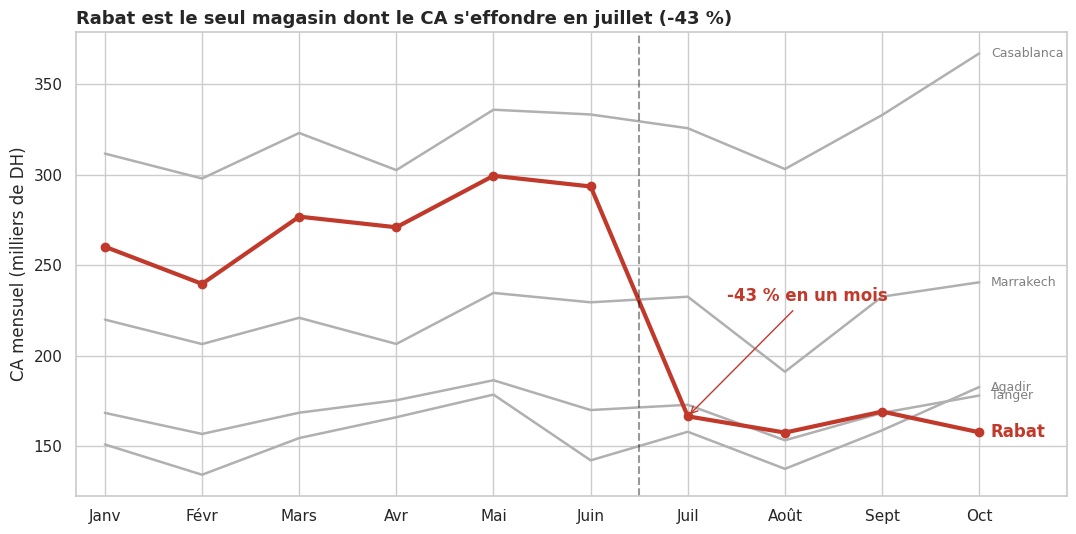

In [27]:
fig, ax = plt.subplots(figsize=(11, 5.5))
for m in autres:
    ax.plot(ca.index, ca[m] / 1000, color=GRIS, linewidth=1.8)
    ax.text(10.12, ca.loc[10, m] / 1000, m, color="grey", va="center", fontsize=9)
ax.plot(ca.index, ca["Rabat"] / 1000, color=ROUGE, linewidth=3, marker="o")
ax.text(10.12, ca.loc[10, "Rabat"] / 1000, "Rabat", color=ROUGE, va="center", fontweight="bold")

ax.axvline(6.5, color="black", linestyle="--", alpha=0.4)
ax.annotate(f"{chute_juillet:.0f} % en un mois", xy=(7, ca.loc[7, "Rabat"] / 1000),
            xytext=(7.4, 230), color=ROUGE, fontweight="bold",
            arrowprops=dict(arrowstyle="->", color=ROUGE))
ax.set_xticks(range(1, 11), MOIS)
ax.set_xlim(0.7, 10.9)
ax.set_ylabel("CA mensuel (milliers de DH)")
ax.set_title(f"Rabat est le seul magasin dont le CA s'effondre en juillet ({chute_juillet:.0f} %)",
             fontsize=13, fontweight="bold", loc="left")
plt.tight_layout()
plt.show()

➡️ **Oui, c'est vrai, et c'est brutal.** Le CA de Rabat passe de **293 448 DH en juin à 166 623 DH en juillet (−43 %)**, puis reste bloqué autour de 160 000 DH jusqu'en octobre. Les 4 autres magasins gardent leur niveau habituel (avec un petit creux d'août commun à tous). Ce n'est pas une érosion lente : il y a une **rupture nette au 1er juillet**.

### Mission 2.2 — L'évolution de chaque magasin
Évolution du **CA mensuel moyen** entre janvier-juin (6 mois) et juillet-octobre (4 mois). On compare des moyennes mensuelles, pas des totaux, car les deux périodes n'ont pas la même durée.

In [28]:
ca_avant = ca.loc[1:6].mean()        # CA mensuel moyen janv-juin
ca_apres = ca.loc[7:10].mean()       # CA mensuel moyen juil-oct
evol = pd.DataFrame({"CA mensuel avant": ca_avant, "CA mensuel après": ca_apres})
evol["evolution_%"] = (ca_apres / ca_avant - 1) * 100
evol = evol.sort_values("evolution_%").reset_index()
evol_rabat = evol.set_index("magasin").loc["Rabat", "evolution_%"]
evol_autres_moy = evol.set_index("magasin").loc[autres, "evolution_%"].mean()
print(evol.round(1))

      magasin  CA mensuel avant  CA mensuel après  evolution_%
0       Rabat        273,409.50        162,837.80       -40.40
1      Tanger        171,032.00        168,249.60        -1.60
2   Marrakech        219,713.90        224,265.70         2.10
3      Agadir        154,538.80        159,372.40         3.10
4  Casablanca        317,308.50        332,093.40         4.70


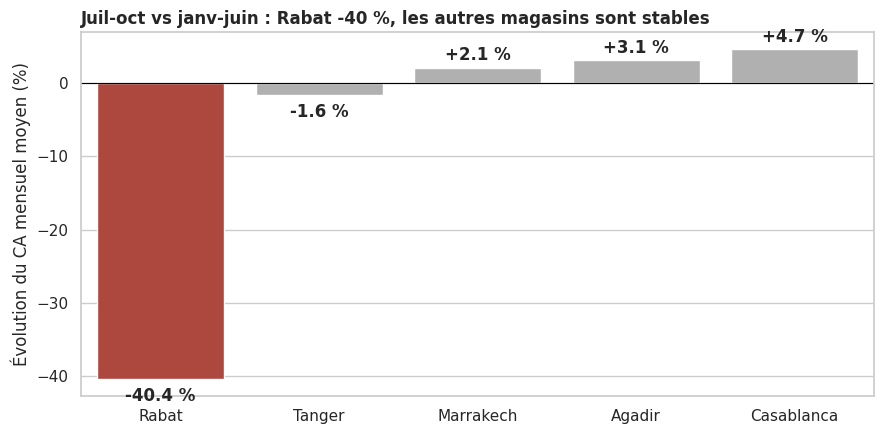

In [29]:
couleurs = {m: (ROUGE if m == "Rabat" else GRIS) for m in evol["magasin"]}
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=evol, x="magasin", y="evolution_%", hue="magasin", palette=couleurs, legend=False, ax=ax)
for i, v in enumerate(evol["evolution_%"]):
    ax.text(i, v + (1 if v >= 0 else -3), f"{v:+.1f} %", ha="center", fontweight="bold")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("")
ax.set_ylabel("Évolution du CA mensuel moyen (%)")
ax.set_title(f"Juil-oct vs janv-juin : Rabat {evol_rabat:+.0f} %, les autres magasins sont stables",
             fontweight="bold", loc="left")
plt.tight_layout()
plt.show()

➡️ Sur la période juillet-octobre, le CA mensuel moyen de Rabat recule de **−40,4 %**, alors que les autres magasins évoluent entre **−1,6 % et +4,7 %** (+2,1 % en moyenne). Le problème est **propre à Rabat**.

### Mission 2.3 — Moins de clients ou des paniers plus petits ?
CA = **nombre de tickets × panier moyen**. Lequel des deux a changé à Rabat ?

In [30]:
nb_mois = pd.Series({"1. Janv-juin": 6, "2. Juil-oct": 4})

tickets_mois = pd.pivot_table(ventes, index="periode", columns="magasin",
                              values="ticket_id", aggfunc="count").div(nb_mois, axis=0)
panier = pd.pivot_table(ventes, index="periode", columns="magasin", values="montant", aggfunc="mean")

tickets_mois.loc["Évolution %"] = (tickets_mois.iloc[1] / tickets_mois.iloc[0] - 1) * 100
panier.loc["Évolution %"] = (panier.iloc[1] / panier.iloc[0] - 1) * 100
evol_tickets_rabat = tickets_mois.loc["Évolution %", "Rabat"]
evol_panier_rabat = panier.loc["Évolution %", "Rabat"]

print("Nombre de tickets par mois")
display(tickets_mois.round(1))
print("Panier moyen (DH)")
display(panier.round(1))

Nombre de tickets par mois


magasin,Agadir,Casablanca,Marrakech,Rabat,Tanger
periode,,,,,
1. Janv-juin,476.00,980.50,675.50,837.30,517.80
2. Juil-oct,475.20,984.80,661.80,503.80,511.00
Évolution %,-0.20,0.40,-2.00,-39.80,-1.30


Panier moyen (DH)


magasin,Agadir,Casablanca,Marrakech,Rabat,Tanger
periode,,,,,
1. Janv-juin,324.70,323.60,325.30,326.50,330.30
2. Juil-oct,335.30,337.20,338.90,323.30,329.30
Évolution %,3.30,4.20,4.20,-1.00,-0.30


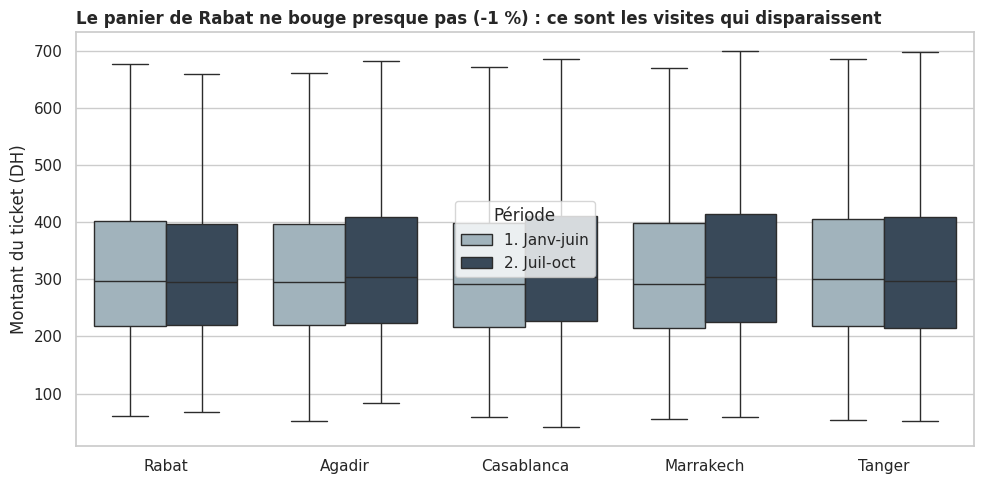

In [31]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=ventes, x="magasin", y="montant", hue="periode", showfliers=False,
            palette=["#9DB4C0", "#34495E"], order=["Rabat"] + autres, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("Montant du ticket (DH)")
ax.legend(title="Période")
ax.set_title(f"Le panier de Rabat ne bouge presque pas ({evol_panier_rabat:+.0f} %) : ce sont les visites qui disparaissent",
             fontweight="bold", loc="left")
plt.tight_layout()
plt.show()

➡️ **Ce sont les visites qui disparaissent, pas les paniers qui rétrécissent.** À Rabat, le nombre de tickets par mois tombe de **837 à 504 (−39,8 %)**, alors que le panier moyen reste quasi stable (**326 → 323 DH, −1,0 %**). Les clients qui viennent encore achètent comme avant ; ce sont les clients **qui ne viennent plus** qui font chuter le CA.

---
## 🔗 PARTIE 3 — La cause

### Mission 3.1 — Explorer les autres fichiers
On cherche ce qui a changé **uniquement à Rabat** et **à partir de juillet**.
- `magasins.csv` ne contient aucune date : il décrit les magasins mais ne peut pas expliquer un changement en juillet.
- `attente_caisse.csv` est daté : c'est le bon candidat. Carte de chaleur de l'attente moyenne par magasin et par mois.

,magasin,ville,surface_m2,nb_caisses,annee_ouverture
0,Casablanca,Casablanca,2400,12,2012
1,Rabat,Rabat,1900,10,2014
2,Marrakech,Marrakech,1700,9,2016
3,Agadir,Agadir,1300,7,2019
4,Tanger,Tanger,1500,8,2018


Attente à Rabat : 4.4 min (janv-juin) → 12.8 min (juil-oct), soit × 2.9
Attente moyenne des autres magasins en juil-oct : 4.9 min


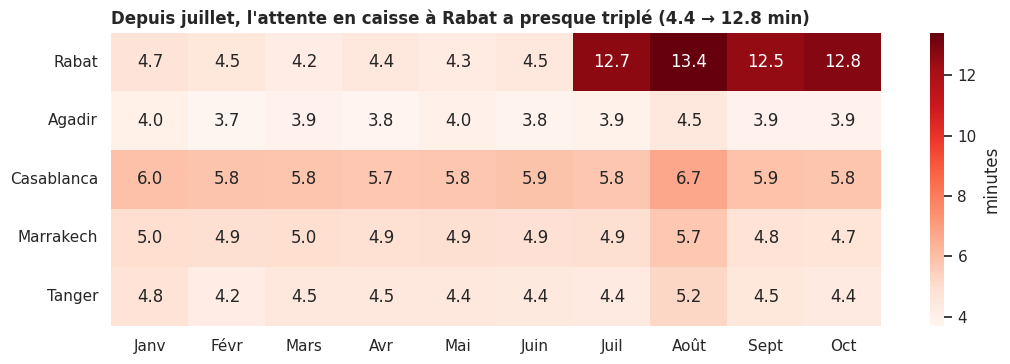

In [32]:
display(magasins)

att_pivot = pd.pivot_table(attente, index="magasin", columns="mois", values="attente_min", aggfunc="mean")
att_pivot = att_pivot.loc[["Rabat"] + autres]
att_rabat_avant = attente[(attente["magasin"] == "Rabat") & (attente["mois"] <= 6)]["attente_min"].mean()
att_rabat_apres = attente[(attente["magasin"] == "Rabat") & (attente["mois"] >= 7)]["attente_min"].mean()
att_autres_apres = attente[(attente["magasin"] != "Rabat") & (attente["mois"] >= 7)]["attente_min"].mean()
print(f"Attente à Rabat : {att_rabat_avant:.1f} min (janv-juin) → {att_rabat_apres:.1f} min (juil-oct), "
      f"soit × {att_rabat_apres / att_rabat_avant:.1f}")
print(f"Attente moyenne des autres magasins en juil-oct : {att_autres_apres:.1f} min")

fig, ax = plt.subplots(figsize=(11, 3.8))
sns.heatmap(att_pivot, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "minutes"},
            xticklabels=MOIS, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title(f"Depuis juillet, l'attente en caisse à Rabat a presque triplé ({att_rabat_avant:.1f} → {att_rabat_apres:.1f} min)",
             fontweight="bold", loc="left")
plt.tight_layout()
plt.show()

➡️ **Un seul changement correspond exactement au profil recherché** : l'attente en caisse à Rabat passe de **4,4 min (janvier-juin) à 12,8 min (juillet-octobre), soit × 2,9**, dès le 1er juillet. Dans les autres magasins, elle reste entre 4 et 6 min (4,9 min en moyenne). Le léger pic d'août (+0,7 min environ) touche tout le monde et reste faible. `magasins.csv` indique 10 caisses à Rabat, mais ce fichier n'est pas daté : il ne dit pas combien de caisses étaient réellement **ouvertes**.

### Mission 3.2 — Fusionner visites et attente
Un tableau avec, pour chaque magasin et chaque mois : le nombre de tickets et l'attente moyenne (`groupby` + `merge`).

In [33]:
visites = ventes.groupby(["magasin", "mois"]).agg(nb_tickets=("ticket_id", "count")).reset_index()
att_mois = attente.groupby(["magasin", "mois"]).agg(attente_moy=("attente_min", "mean")).reset_index()

fusion = visites.merge(att_mois, on=["magasin", "mois"])
print(fusion.shape)
fusion[fusion["magasin"] == "Rabat"].round(1)

(50, 4)


,magasin,mois,nb_tickets,attente_moy
30,Rabat,1,820,4.70
31,Rabat,2,751,4.60
32,Rabat,3,856,4.20
33,Rabat,4,848,4.40
34,Rabat,5,880,4.30
35,Rabat,6,869,4.50
36,Rabat,7,533,12.70
37,Rabat,8,478,13.40
38,Rabat,9,519,12.50
39,Rabat,10,485,12.80


➡️ Le tableau fusionné contient 50 lignes (5 magasins × 10 mois). Pour Rabat, on voit déjà les deux colonnes basculer ensemble en juillet : les tickets baissent quand l'attente monte.

### Mission 3.3 — Mesurer le lien
Pour Rabat : nuage de points avec droite de tendance (Seaborn) et corrélation (NumPy).

Corrélation attente / tickets à Rabat : mensuelle -0.98 | journalière -0.66


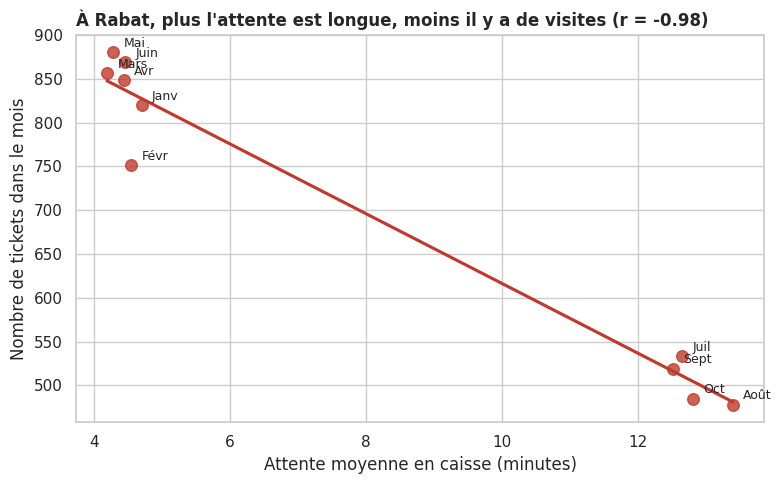

In [34]:
rabat_m = fusion[fusion["magasin"] == "Rabat"]
corr = np.corrcoef(rabat_m["attente_moy"], rabat_m["nb_tickets"])[0, 1]

# Contrôle sur les données journalières de Rabat (plus de points)
jour_rabat = (ventes[ventes["magasin"] == "Rabat"].groupby("date").size().rename("tickets").reset_index()
              .merge(attente[attente["magasin"] == "Rabat"][["date", "attente_min"]], on="date").dropna())
corr_jour = np.corrcoef(jour_rabat["attente_min"], jour_rabat["tickets"])[0, 1]
print(f"Corrélation attente / tickets à Rabat : mensuelle {corr:.2f} | journalière {corr_jour:.2f}")

fig, ax = plt.subplots(figsize=(8, 5))
sns.regplot(data=rabat_m, x="attente_moy", y="nb_tickets", color=ROUGE, ci=None,
            scatter_kws={"s": 70}, ax=ax)
for _, r in rabat_m.iterrows():
    ax.text(r["attente_moy"] + 0.15, r["nb_tickets"] + 6, MOIS[int(r["mois"]) - 1], fontsize=9)
ax.set_xlabel("Attente moyenne en caisse (minutes)")
ax.set_ylabel("Nombre de tickets dans le mois")
ax.set_title(f"À Rabat, plus l'attente est longue, moins il y a de visites (r = {corr:.2f})",
             fontweight="bold", loc="left")
plt.tight_layout()
plt.show()

➡️ La corrélation entre l'attente et le nombre de tickets à Rabat est **−0,98** sur les 10 mois (−0,66 sur les 304 jours). Les points forment deux groupes nets : janvier-juin (≈ 4,5 min, ≈ 840 tickets) et juillet-octobre (≈ 13 min, ≈ 500 tickets).

**Une corrélation suffit-elle à prouver une cause ? Non.** Deux choses peuvent bouger ensemble par hasard ou à cause d'un troisième facteur. Ici, la cause est crédible parce que **tout concorde** : même date de début (juillet), même lieu (Rabat seulement), mécanisme logique (une file trop longue décourage les clients), et tous les autres suspects sont écartés chiffres à l'appui (mission 3.4).

### Mission 3.4 — Juger chaque suspect
Une phrase + un chiffre qui accuse ou innocente chaque suspect.

In [35]:
# Suspect 1 : l'été -> les autres magasins baissent-ils aussi ?
# (evol_autres_moy calculé en 2.2)

# Suspect 2 : la hausse des prix de mai -> panier moyen avant/après mai, tous magasins
panier_janv_avr = ventes[ventes["mois"] <= 4]["montant"].mean()
panier_mai_juin = ventes[ventes["mois"].isin([5, 6])]["montant"].mean()
hausse_prix = (panier_mai_juin / panier_janv_avr - 1) * 100
tickets_rabat_mai_juin = ventes[(ventes["magasin"] == "Rabat") & ventes["mois"].isin([5, 6])].shape[0] / 2
tickets_rabat_janv_avr = ventes[(ventes["magasin"] == "Rabat") & (ventes["mois"] <= 4)].shape[0] / 4

# Suspect 5 : fermeture -> nombre de jours avec des ventes à Rabat
jours_ouverts = ventes[ventes["magasin"] == "Rabat"].groupby("mois")["date"].nunique()

verdicts = pd.DataFrame([
    ["L'été", f"Les autres magasins évoluent de {evol_autres_moy:+.1f} % en moyenne sur juil-oct (Rabat {evol_rabat:+.0f} %)", "Innocent"],
    ["Hausse des prix de mai", f"Le panier monte de {hausse_prix:+.1f} % partout en mai-juin, mais Rabat garde {tickets_rabat_mai_juin:.0f} tickets/mois (vs {tickets_rabat_janv_avr:.0f} avant) : la chute ne commence qu'en juillet", "Innocent"],
    ["Paniers plus petits", f"Panier de Rabat {evol_panier_rabat:+.1f} % contre {evol_tickets_rabat:+.1f} % pour le nombre de tickets", "Innocent"],
    ["Fermeture du magasin", f"Rabat a vendu tous les jours : {jours_ouverts.min()} à {jours_ouverts.max()} jours d'ouverture par mois", "Innocent"],
    ["Attente en caisse", f"{att_rabat_avant:.1f} → {att_rabat_apres:.1f} min à Rabat seulement, dès juillet ; corrélation {corr:.2f}", "COUPABLE"],
], columns=["Suspect", "Le chiffre", "Verdict"])
verdicts

,Suspect,Le chiffre,Verdict
0,L'été,Les autres magasins évoluent de +2.1 % en moye...,Innocent
1,Hausse des prix de mai,"Le panier monte de +5.6 % partout en mai-juin,...",Innocent
2,Paniers plus petits,Panier de Rabat -1.0 % contre -39.8 % pour le ...,Innocent
3,Fermeture du magasin,Rabat a vendu tous les jours : 28 à 31 jours d...,Innocent
4,Attente en caisse,"4.4 → 12.8 min à Rabat seulement, dès juillet ...",COUPABLE


➡️ **Verdict : l'attente en caisse est coupable.** L'été est innocenté (les autres magasins ne baissent pas), la hausse des prix de mai aussi (Rabat continue à bien vendre en mai-juin), les paniers ne rétrécissent pas, et le magasin a été ouvert tous les jours.

🛑 *Point d'étape n°2 : c'est la conclusion à présenter au formateur pour obtenir les informations RH et opérations de la partie 6.*

---
## 👥 PARTIE 4 — Qui est parti ? Segmenter les clients fidèles

### Mission 4.1 — Les clients fidèles actifs
Combien de clients fidèles **différents** viennent chaque mois, par magasin ?

In [36]:
fideles = ventes[ventes["client_id"].notna()]
actifs = pd.pivot_table(fideles, index="mois", columns="magasin", values="client_id", aggfunc="nunique")
actifs_juin_rabat, actifs_oct_rabat = actifs.loc[6, "Rabat"], actifs.loc[10, "Rabat"]
evol_actifs_rabat = (actifs_oct_rabat / actifs_juin_rabat - 1) * 100
evol_actifs_autres = (actifs.loc[10, autres].sum() / actifs.loc[6, autres].sum() - 1) * 100
print(f"Clients fidèles actifs à Rabat : {actifs_juin_rabat} en juin → {actifs_oct_rabat} en octobre ({evol_actifs_rabat:+.0f} %)")
print(f"Autres magasins (ensemble) : {evol_actifs_autres:+.0f} % sur la même période")
print("Chaque client fidèle n'achète que dans un seul magasin :",
      (fideles.groupby("client_id")["magasin"].nunique() == 1).all())
actifs

Clients fidèles actifs à Rabat : 289 en juin → 185 en octobre (-36 %)
Autres magasins (ensemble) : +1 % sur la même période
Chaque client fidèle n'achète que dans un seul magasin : True


magasin,Agadir,Casablanca,Marrakech,Rabat,Tanger
mois,,,,,
1,169,354,234,285,179
2,148,349,223,274,172
3,166,346,229,296,180
4,160,336,220,286,181
5,161,353,221,298,180
6,154,352,245,289,175
7,157,346,222,199,171
8,153,335,217,195,168
9,177,342,235,201,174


➡️ Rabat passe de **289 clients fidèles actifs en juin à 185 en octobre (−36 %)**, alors que les autres magasins sont stables (+1 %). Chaque client fidèle n'achète que dans **un seul magasin** : les clients de Rabat ne sont pas partis vers un autre MarchéPlus, ils sont **sortis de l'enseigne**.

### Mission 4.2 — Créer des segments de clients
Sur **janvier-juin** (avant le problème) : nombre de visites et montant total par client fidèle, puis 3 segments avec `np.select` :
**Piliers** (≥ 15 visites) · **Réguliers** (8 à 14) · **Occasionnels** (< 8).

In [37]:
profil = (fideles[fideles["mois"] <= 6]
          .groupby(["client_id", "magasin"])
          .agg(visites=("ticket_id", "count"), montant=("montant", "sum"))
          .reset_index())

conditions = [profil["visites"] >= 15, profil["visites"] >= 8]
profil["segment"] = np.select(conditions, ["Piliers", "Réguliers"], "Occasionnels")
profil["zone"] = np.where(profil["magasin"] == "Rabat", "Rabat", "Autres magasins")

ORDRE_SEG = ["Piliers", "Réguliers", "Occasionnels"]
resume_seg = pd.pivot_table(profil, index="segment", columns="zone", values="client_id", aggfunc="count").loc[ORDRE_SEG]
print("Nombre de clients par segment :")
display(resume_seg)
print("Montant moyen dépensé en janv-juin par segment (DH) :")
profil.groupby("segment")["montant"].mean().loc[ORDRE_SEG].round(0)

Nombre de clients par segment :


zone,Autres magasins,Rabat
segment,,
Piliers,177,59
Réguliers,500,144
Occasionnels,625,211


Montant moyen dépensé en janv-juin par segment (DH) :


,montant
segment,
Piliers,"6,327.00"
Réguliers,"3,417.00"
Occasionnels,"1,409.00"


➡️ Les **Piliers** sont peu nombreux mais dépensent en 6 mois plusieurs fois plus qu'un Occasionnel : ce sont les clients qu'un magasin ne peut pas se permettre de perdre.

### Mission 4.3 — Le taux de rétention par segment
Un client est **retenu** s'il est revenu dans son magasin en **septembre-octobre**.

Rétention globale : Rabat 62 % | autres magasins 87 %


zone,Autres magasins,Rabat
segment,,
Piliers,100.00,44.10
Réguliers,94.40,70.10
Occasionnels,77.90,61.60


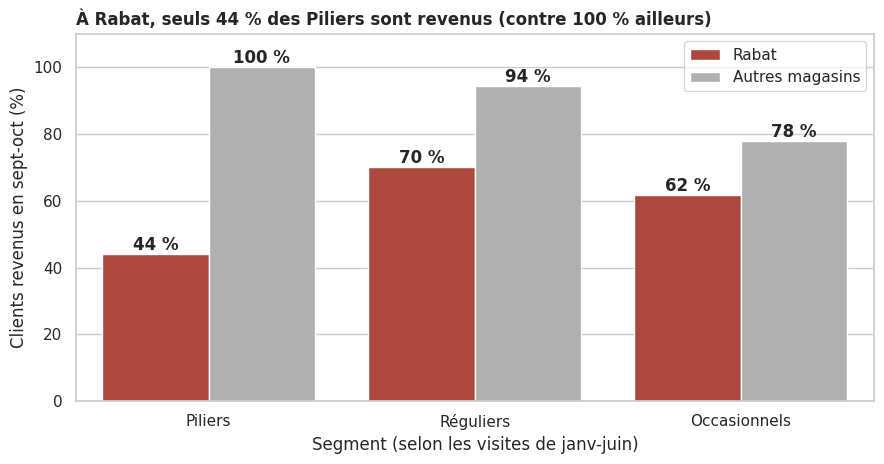

In [38]:
couples_sept_oct = fideles[fideles["mois"] >= 9][["client_id", "magasin"]].drop_duplicates()
cle_retenus = couples_sept_oct["client_id"] + "_" + couples_sept_oct["magasin"]
profil["retenu"] = np.where((profil["client_id"] + "_" + profil["magasin"]).isin(cle_retenus), 1, 0)

retention = pd.pivot_table(profil, index="segment", columns="zone", values="retenu", aggfunc="mean").loc[ORDRE_SEG] * 100
ret_piliers_rabat = retention.loc["Piliers", "Rabat"]
ret_piliers_autres = retention.loc["Piliers", "Autres magasins"]
ret_rabat = profil[profil["zone"] == "Rabat"]["retenu"].mean() * 100
ret_autres = profil[profil["zone"] != "Rabat"]["retenu"].mean() * 100
print(f"Rétention globale : Rabat {ret_rabat:.0f} % | autres magasins {ret_autres:.0f} %")
display(retention.round(1))

ret_long = retention.reset_index().melt(id_vars="segment", var_name="zone", value_name="retention")
fig, ax = plt.subplots(figsize=(9, 4.8))
sns.barplot(data=ret_long, x="segment", y="retention", hue="zone", order=ORDRE_SEG,
            hue_order=["Rabat", "Autres magasins"], palette={"Rabat": ROUGE, "Autres magasins": GRIS}, ax=ax)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.0f %%", fontweight="bold")
ax.set_ylim(0, 110)
ax.set_xlabel("Segment (selon les visites de janv-juin)")
ax.set_ylabel("Clients revenus en sept-oct (%)")
ax.legend(title="")
ax.set_title(f"À Rabat, seuls {ret_piliers_rabat:.0f} % des Piliers sont revenus (contre {ret_piliers_autres:.0f} % ailleurs)",
             fontweight="bold", loc="left")
plt.tight_layout()
plt.show()

➡️ **Ce sont les meilleurs clients qui sont le plus partis.** À Rabat, seuls **44 % des Piliers** sont revenus en septembre-octobre, contre **100 %** dans les autres magasins. La rétention globale est de 62 % à Rabat contre 87 % ailleurs. Logique : un client qui vient 3 à 4 fois par mois subit l'attente bien plus souvent qu'un client occasionnel. Or un Pilier dépense en moyenne **6 327 DH en 6 mois**, 4,5 fois plus qu'un Occasionnel (1 409 DH).

---
## 📅 PARTIE 5 — Quand le problème est-il le pire ?

### Mission 5.1 — L'attente selon le jour de la semaine
À Rabat, attente moyenne par jour de la semaine, avant et après juillet.

Depuis juillet : 15.4 min le vendredi-samedi contre 11.8 min les autres jours


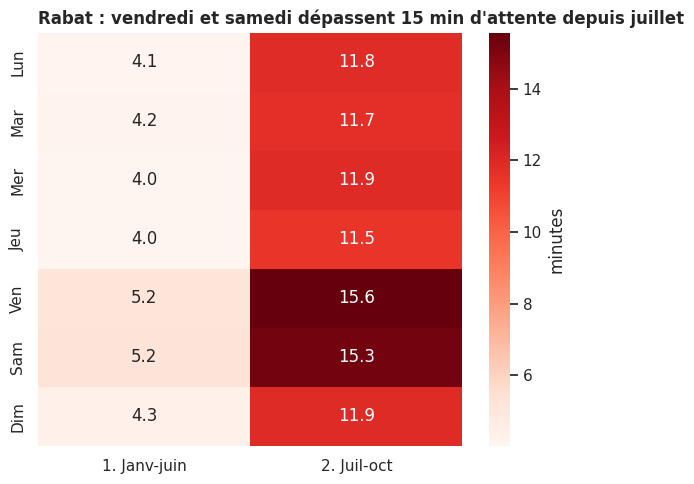

In [39]:
att_jour = pd.pivot_table(attente[attente["magasin"] == "Rabat"], index="jour", columns="periode",
                          values="attente_min", aggfunc="mean")
att_jour.index = JOURS
att_jour["Hausse (min)"] = att_jour["2. Juil-oct"] - att_jour["1. Janv-juin"]
att_ven_sam = att_jour.loc[["Ven", "Sam"], "2. Juil-oct"].mean()
att_semaine = att_jour.loc[["Lun", "Mar", "Mer", "Jeu", "Dim"], "2. Juil-oct"].mean()
print(f"Depuis juillet : {att_ven_sam:.1f} min le vendredi-samedi contre {att_semaine:.1f} min les autres jours")

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(att_jour[["1. Janv-juin", "2. Juil-oct"]], annot=True, fmt=".1f", cmap="Reds",
            cbar_kws={"label": "minutes"}, ax=ax)
ax.set_title(f"Rabat : vendredi et samedi dépassent {att_ven_sam:.0f} min d'attente depuis juillet",
             fontweight="bold", loc="left")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

➡️ Depuis juillet, l'attente à Rabat atteint **15,4 min le vendredi et le samedi**, contre 11,8 min les autres jours. Avant juillet, ces deux jours étaient déjà les plus chargés, mais restaient autour de 5 à 6 min.

### Mission 5.2 — Les visites perdues selon le jour
Nombre moyen de tickets **par jour** (lundi, mardi…) avant et après juillet, puis baisse en %.
⚠️ Les périodes n'ont pas la même durée : on compare des **moyennes par jour**, pas des totaux.

periode,1. Janv-juin,2. Juil-oct,Baisse %,Autres magasins %
Lun,25.00,15.60,-37.50,-4.30
Mar,26.50,17.50,-33.90,4.40
Mer,25.60,16.90,-33.80,-2.30
Jeu,25.80,15.80,-38.60,-9.10
Ven,33.00,16.40,-50.10,-0.20
Sam,32.90,15.40,-53.20,-5.80
Dim,25.40,16.90,-33.40,-0.30


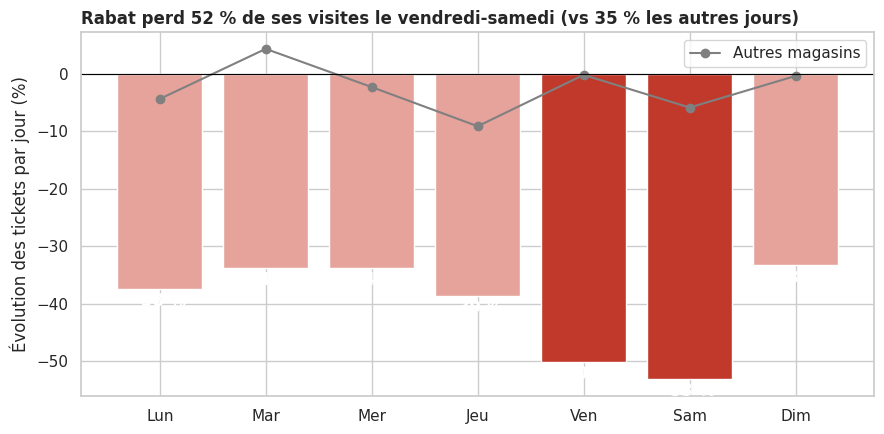

In [40]:
par_date = ventes.groupby(["magasin", "date", "jour", "periode"]).size().rename("tickets").reset_index()
par_date["zone"] = np.where(par_date["magasin"] == "Rabat", "Rabat", "Autres magasins")

# Rabat : tickets moyens par jour de la semaine
moy_rabat = pd.pivot_table(par_date[par_date["zone"] == "Rabat"], index="jour", columns="periode",
                           values="tickets", aggfunc="mean")
moy_rabat.index = JOURS
moy_rabat["Baisse %"] = (moy_rabat["2. Juil-oct"] / moy_rabat["1. Janv-juin"] - 1) * 100

# Autres magasins : même calcul (moyenne par magasin et par jour)
moy_autres = pd.pivot_table(par_date[par_date["zone"] != "Rabat"], index="jour", columns="periode",
                            values="tickets", aggfunc="mean")
moy_autres.index = JOURS
moy_rabat["Autres magasins %"] = (moy_autres["2. Juil-oct"] / moy_autres["1. Janv-juin"] - 1) * 100
baisse_ven_sam = moy_rabat.loc[["Ven", "Sam"], "Baisse %"].mean()
baisse_semaine = moy_rabat.loc[["Lun", "Mar", "Mer", "Jeu", "Dim"], "Baisse %"].mean()
display(moy_rabat.round(1))

fig, ax = plt.subplots(figsize=(9, 4.5))
couleurs_j = [ROUGE if j in ["Ven", "Sam"] else "#E6A39B" for j in JOURS]
ax.bar(JOURS, moy_rabat["Baisse %"], color=couleurs_j)
ax.plot(JOURS, moy_rabat["Autres magasins %"], color="grey", marker="o", label="Autres magasins")
for i, v in enumerate(moy_rabat["Baisse %"]):
    ax.text(i, v - 3, f"{v:.0f} %", ha="center", color="white", fontweight="bold")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Évolution des tickets par jour (%)")
ax.legend()
ax.set_title(f"Rabat perd {-baisse_ven_sam:.0f} % de ses visites le vendredi-samedi (vs {-baisse_semaine:.0f} % les autres jours)",
             fontweight="bold", loc="left")
plt.tight_layout()
plt.show()

➡️ **Le problème est le pire le vendredi et le samedi** : Rabat y perd **52 % de ses visites** en moyenne, contre **35 %** les autres jours. Ce sont les jours où il y a le plus de monde, donc le plus d'attente, donc le plus de clients perdus. Les autres magasins, eux, restent stables tous les jours de la semaine (entre −9 % et +4 %).

---
## 💰 PARTIE 6 — Combien ça coûte ?

### Mission 6.1 — CA et marge perdus
**Méthode** : pour chaque mois de juillet à octobre, on suppose que Rabat aurait suivi la même évolution que les 4 autres magasins par rapport à leur moyenne de janvier-juin (cela tient compte de la saisonnalité, par exemple le creux d'août). CA perdu = CA attendu − CA réel ; marge perdue = 21 % du CA perdu.

In [41]:
indice_autres = ca[autres].sum(axis=1) / ca.loc[1:6, autres].sum(axis=1).mean()   # 1.00 = niveau moyen janv-juin
cout = pd.DataFrame({
    "CA réel": ca.loc[7:10, "Rabat"],
    "CA attendu": ca_avant["Rabat"] * indice_autres.loc[7:10],
})
cout["CA perdu"] = cout["CA attendu"] - cout["CA réel"]
cout["Marge perdue"] = cout["CA perdu"] * MARGE
cout.index = MOIS[6:10]

ca_perdu_total = cout["CA perdu"].sum()
marge_perdue_total = cout["Marge perdue"].sum()
marge_perdue_mois = cout["Marge perdue"].mean()
ca_perdu_mois = cout["CA perdu"].mean()
print(f"CA perdu juil-oct : {dh(ca_perdu_total)} (≈ {dh(ca_perdu_mois)} par mois)")
print(f"Marge perdue      : {dh(marge_perdue_total)} (≈ {dh(marge_perdue_mois)} par mois)")
cout.round(0)

CA perdu juil-oct : 469 404 DH (≈ 117 351 DH par mois)
Marge perdue      : 98 575 DH (≈ 24 644 DH par mois)


,CA réel,CA attendu,CA perdu,Marge perdue
Juil,"166,623.00","281,873.00","115,250.00","24,203.00"
Août,"157,653.00","248,924.00","91,271.00","19,167.00"
Sept,"169,254.00","283,028.00","113,774.00","23,893.00"
Oct,"157,821.00","306,929.00","149,108.00","31,313.00"


➡️ Si Rabat avait suivi la même évolution que les autres magasins, il aurait fait environ **1 120 754 DH** de CA entre juillet et octobre au lieu de 651 351 DH. **CA perdu : 469 404 DH sur 4 mois, soit ≈ 117 000 DH par mois. Marge perdue : 98 575 DH, soit ≈ 24 644 DH par mois.** Octobre est le pire mois (31 313 DH de marge perdue) : la perte ne se résorbe pas, elle s'aggrave.

### Mission 6.2 — L'information du service RH et des opérations

> 🔒 **À compléter avec les informations données par le formateur au point d'étape n°2.**
> En attendant, les deux paramètres ci-dessous sont des **hypothèses de travail** cohérentes avec les données (5 scénarios de 0 à 3 caisses rouvertes → 3 caisses fermées). **Il suffit de modifier ces deux lignes : tout le reste du notebook se recalcule.**

In [42]:
# ⚠️ HYPOTHÈSES À REMPLACER par les chiffres RH / opérations du formateur
caisses_fermees = 3       # caisses fermées à Rabat début juillet (10 → 7) pour réduire la masse salariale
cout_caisse_mois = 4500   # coût mensuel d'une caisse ouverte = salaire chargé d'un(e) caissier(ère), en DH

economie_mois = caisses_fermees * cout_caisse_mois
ratio_cout = marge_perdue_mois / economie_mois
print(f"Économie réalisée sur les salaires : {dh(economie_mois)} par mois")
print(f"Marge perdue à cause de l'attente  : {dh(marge_perdue_mois)} par mois")
print(f"➡️ Chaque dirham « économisé » coûte {ratio_cout:.1f} DH de marge perdue "
      f"(perte nette : {dh(marge_perdue_mois - economie_mois)} par mois)")

Économie réalisée sur les salaires : 13 500 DH par mois
Marge perdue à cause de l'attente  : 24 644 DH par mois
➡️ Chaque dirham « économisé » coûte 1.8 DH de marge perdue (perte nette : 11 144 DH par mois)


➡️ *(Avec les hypothèses actuelles.)* La fermeture de 3 caisses fait économiser **13 500 DH de salaires par mois**, mais fait perdre **24 644 DH de marge par mois**. **Chaque dirham économisé en coûte 1,8 en marge perdue** : une perte nette d'environ **11 000 DH par mois**, sans compter les clients fidèles qui risquent de ne jamais revenir.

⚠️ *Remplacez les deux hypothèses par les chiffres du formateur, réexécutez le notebook, et mettez à jour cette phrase.*

---
## 🧪 PARTIE 7 — Que faire ? Simuler des scénarios

### Mission 7.1 — Modéliser le lien attente → visites
Régression linéaire avec NumPy sur les 10 mois de Rabat : `pente, origine = np.polyfit(x, y, 1)`.

In [43]:
pente, origine = np.polyfit(rabat_m["attente_moy"], rabat_m["nb_tickets"], 1)
print(f"Nombre de tickets/mois ≈ {origine:.0f} {pente:+.1f} × attente (min)")
print(f"➡️ Chaque minute d'attente en plus fait perdre environ {-pente:.0f} tickets par mois à Rabat.")

Nombre de tickets/mois ≈ 1015 -39.8 × attente (min)
➡️ Chaque minute d'attente en plus fait perdre environ 40 tickets par mois à Rabat.


➡️ La pente vaut environ **−40** : à Rabat, **chaque minute d'attente supplémentaire fait perdre environ 40 tickets par mois**. Le passage de 4,4 à 12,8 min explique donc à lui seul une perte d'environ 335 tickets par mois, très proche de la baisse observée (837 → 504, soit −333).

### Mission 7.2 — Comparer 4 scénarios : rouvrir 0, 1, 2 ou 3 caisses
**Hypothèses** : chaque caisse rouverte réduit l'attente de la même quantité (le gain total des 3 caisses = l'écart entre l'attente actuelle et celle d'avant juillet) ; les tickets regagnés suivent la pente de la mission 7.1 ; on valorise au panier moyen de Rabat depuis juillet.

In [44]:
gain_par_caisse = (att_rabat_apres - att_rabat_avant) / caisses_fermees   # minutes gagnées par caisse rouverte
panier_rabat = ventes[(ventes["magasin"] == "Rabat") & (ventes["mois"] >= 7)]["montant"].mean()
print(f"Gain d'attente par caisse rouverte : {gain_par_caisse:.1f} min | panier moyen Rabat depuis juillet : {panier_rabat:.0f} DH")

scenarios = pd.DataFrame({"caisses_rouvertes": [0, 1, 2, 3]})
scenarios["attente_estimee"] = att_rabat_apres - scenarios["caisses_rouvertes"] * gain_par_caisse
scenarios["tickets_regagnes_mois"] = pente * (scenarios["attente_estimee"] - att_rabat_apres)
scenarios["ca_regagne"] = scenarios["tickets_regagnes_mois"] * panier_rabat
scenarios["marge_regagnee"] = scenarios["ca_regagne"] * MARGE
scenarios["cout"] = scenarios["caisses_rouvertes"] * cout_caisse_mois
scenarios["gain_net_mois"] = scenarios["marge_regagnee"] - scenarios["cout"]
meilleur = scenarios.loc[scenarios["gain_net_mois"].idxmax()]
scenarios.round(1)

Gain d'attente par caisse rouverte : 2.8 min | panier moyen Rabat depuis juillet : 323 DH


,caisses_rouvertes,attente_estimee,tickets_regagnes_mois,ca_regagne,marge_regagnee,cout,gain_net_mois
0,0,12.80,-0.00,-0.00,-0.00,0,-0.00
1,1,10.00,111.60,"36,076.80","7,576.10",4500,"3,076.10"
2,2,7.20,223.20,"72,153.60","15,152.20",9000,"6,152.20"
3,3,4.40,334.80,"108,230.30","22,728.40",13500,"9,228.40"


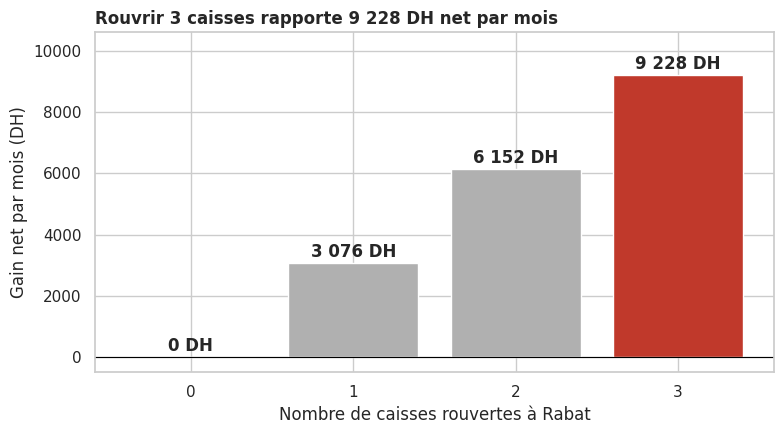

In [45]:
fig, ax = plt.subplots(figsize=(8, 4.5))
couleurs_s = [ROUGE if k == meilleur["caisses_rouvertes"] else GRIS for k in scenarios["caisses_rouvertes"]]
ax.bar(scenarios["caisses_rouvertes"].astype(str), scenarios["gain_net_mois"], color=couleurs_s)
for i, v in enumerate(scenarios["gain_net_mois"]):
    ax.text(i, v + 200, "0 DH" if abs(v) < 1 else dh(v), ha="center", fontweight="bold")
ax.set_ylim(min(0, scenarios["gain_net_mois"].min()) - 500, scenarios["gain_net_mois"].max() * 1.15)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Nombre de caisses rouvertes à Rabat")
ax.set_ylabel("Gain net par mois (DH)")
ax.set_title(f"Rouvrir {int(meilleur['caisses_rouvertes'])} caisses rapporte {dh(meilleur['gain_net_mois'])} net par mois",
             fontweight="bold", loc="left")
plt.tight_layout()
plt.show()

➡️ **Tous les scénarios sont rentables, et rouvrir les 3 caisses est le meilleur** : l'attente redescend à ≈ 4,4 min et le magasin regagne ≈ 335 tickets par mois, soit **+22 728 DH de marge pour 13 500 DH de coût : gain net ≈ 9 200 DH par mois** (≈ 110 000 DH par an). Rouvrir seulement 2 caisses ramène déjà l'attente à ≈ 7,2 min.

**Limites honnêtes** : le modèle repose sur 10 points mensuels et suppose que les clients partis reviendront dès que l'attente baisse ; une partie des Piliers perdus devra sans doute être **relancée** (voir le bonus).

---
## 🖼️ PARTIE 8 — Le tableau de bord du comité de direction

4 graphiques sur une seule figure : **le constat**, **la cause**, **qui est parti**, **la solution**. Chaque titre dit la conclusion.

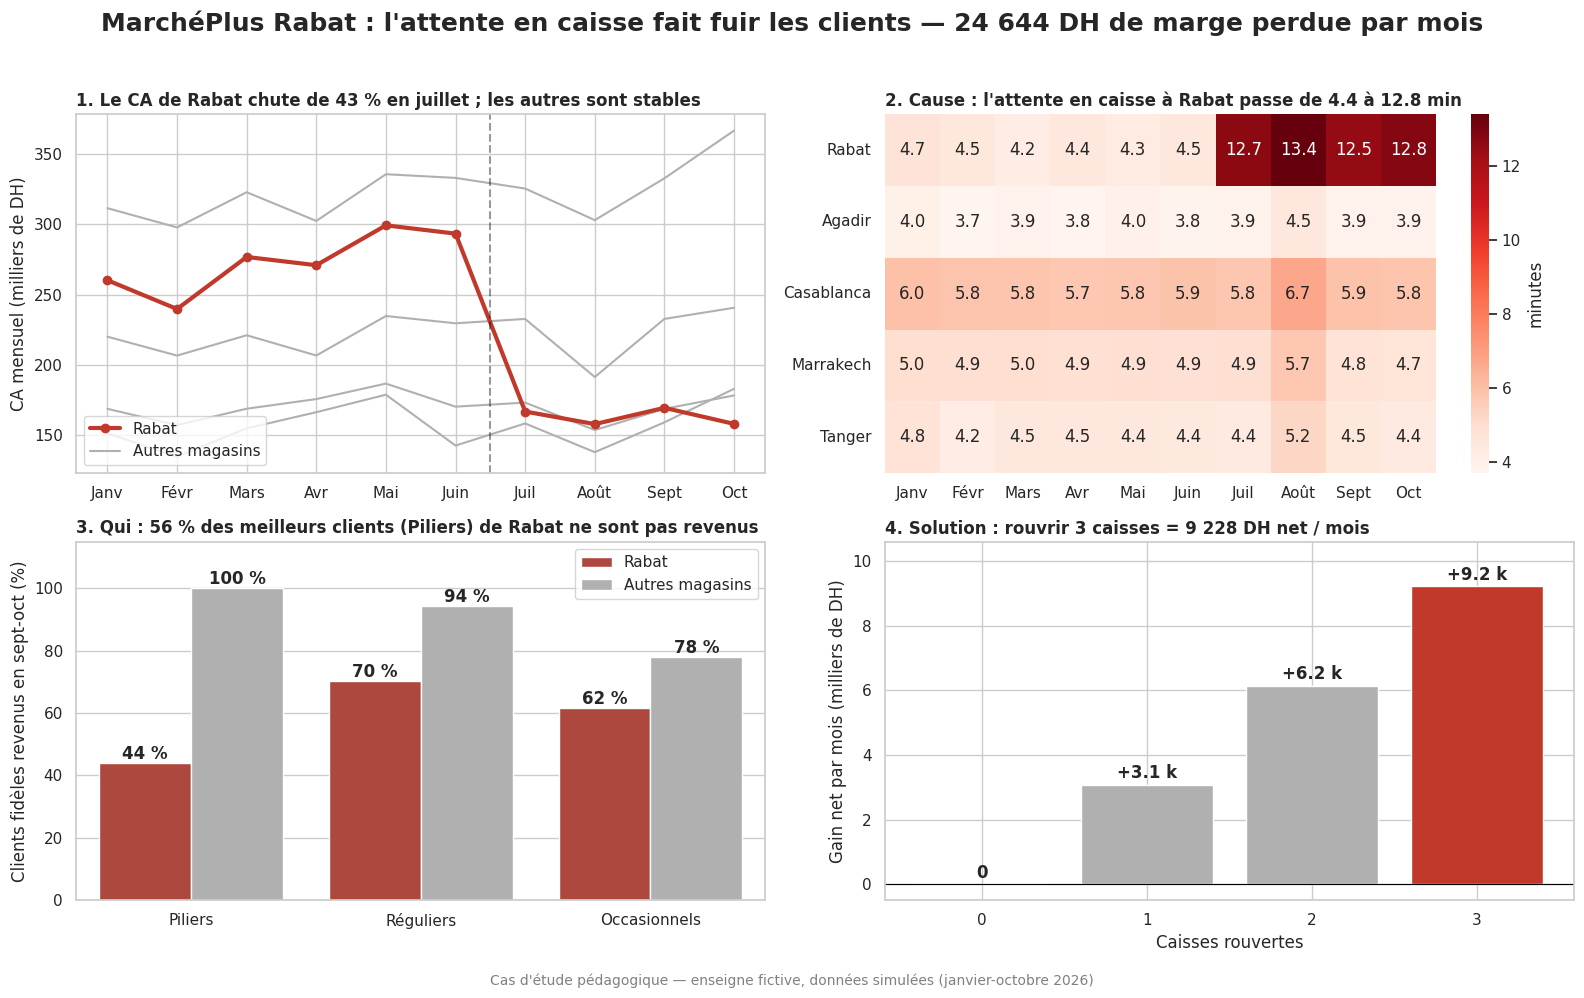

In [46]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Le constat : CA mensuel
ax = axes[0, 0]
for m in autres:
    ax.plot(ca.index, ca[m] / 1000, color=GRIS, linewidth=1.5)
ax.plot(ca.index, ca["Rabat"] / 1000, color=ROUGE, linewidth=3, marker="o", label="Rabat")
ax.plot([], [], color=GRIS, label="Autres magasins")
ax.axvline(6.5, color="black", linestyle="--", alpha=0.4)
ax.set_xticks(range(1, 11), MOIS)
ax.set_ylabel("CA mensuel (milliers de DH)")
ax.legend(loc="lower left")
ax.set_title(f"1. Le CA de Rabat chute de {-chute_juillet:.0f} % en juillet ; les autres sont stables",
             fontweight="bold", loc="left")

# 2. La cause : attente
ax = axes[0, 1]
sns.heatmap(att_pivot, annot=True, fmt=".1f", cmap="Reds", xticklabels=MOIS,
            cbar_kws={"label": "minutes"}, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title(f"2. Cause : l'attente en caisse à Rabat passe de {att_rabat_avant:.1f} à {att_rabat_apres:.1f} min",
             fontweight="bold", loc="left")

# 3. Qui : rétention par segment
ax = axes[1, 0]
sns.barplot(data=ret_long, x="segment", y="retention", hue="zone", order=ORDRE_SEG,
            hue_order=["Rabat", "Autres magasins"], palette={"Rabat": ROUGE, "Autres magasins": GRIS}, ax=ax)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.0f %%", fontweight="bold")
ax.set_ylim(0, 115)
ax.set_xlabel("")
ax.set_ylabel("Clients fidèles revenus en sept-oct (%)")
ax.legend(title="", loc="upper right")
ax.set_title(f"3. Qui : {100 - ret_piliers_rabat:.0f} % des meilleurs clients (Piliers) de Rabat ne sont pas revenus",
             fontweight="bold", loc="left")

# 4. La solution : scénarios
ax = axes[1, 1]
ax.bar(scenarios["caisses_rouvertes"].astype(str), scenarios["gain_net_mois"] / 1000, color=couleurs_s)
for i, v in enumerate(scenarios["gain_net_mois"]):
    ax.text(i, v / 1000 + 0.2, "0" if abs(v) < 1 else f"{v / 1000:+.1f} k", ha="center", fontweight="bold")
ax.set_ylim(min(0, scenarios["gain_net_mois"].min() / 1000) - 0.5, scenarios["gain_net_mois"].max() / 1000 * 1.15)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Caisses rouvertes")
ax.set_ylabel("Gain net par mois (milliers de DH)")
ax.set_title(f"4. Solution : rouvrir {int(meilleur['caisses_rouvertes'])} caisses = {dh(meilleur['gain_net_mois'])} net / mois",
             fontweight="bold", loc="left")

fig.suptitle(f"MarchéPlus Rabat : l'attente en caisse fait fuir les clients — {dh(marge_perdue_mois)} de marge perdue par mois",
             fontsize=18, fontweight="bold")
fig.text(0.5, 0.005, "Cas d'étude pédagogique — enseigne fictive, données simulées (janvier-octobre 2026)",
         ha="center", fontsize=10, color="grey")
plt.tight_layout(rect=[0, 0.02, 1, 0.96])
fig.savefig(IMG + "tableau_de_bord.png", dpi=200, bbox_inches="tight")
plt.show()

➡️ Le tableau de bord est enregistré dans `images/tableau_de_bord.png`. Il se lit en 10 secondes, de gauche à droite et de haut en bas : **constat → cause → qui → solution**.

---
## 💡 PARTIE 9 — Ma question personnelle

### ❓ À partir de combien de minutes d'attente les clients décrochent-ils ?

La partie 7 dit « rouvrir des caisses ». Mais un directeur de magasin a besoin d'un **objectif opérationnel** : quelle attente maximale viser ? Et les autres magasins sont-ils à l'abri ?

**Méthode** : pour chaque magasin et chaque jour, je calcule un **indice de fréquentation** = tickets du jour ÷ moyenne habituelle du même magasin, le même jour de la semaine, en janvier-juin (100 = journée normale). Je regarde ensuite cet indice selon l'attente du jour, sur les 5 magasins (≈ 1 500 journées).

In [47]:
jours_mag = ventes.groupby(["magasin", "date", "jour", "mois"]).size().rename("tickets").reset_index()
reference = (jours_mag[jours_mag["mois"] <= 6].groupby(["magasin", "jour"])["tickets"]
             .mean().rename("tickets_habituels").reset_index())
jours_mag = (jours_mag.merge(reference, on=["magasin", "jour"])
             .merge(attente[["magasin", "date", "attente_min"]], on=["magasin", "date"])
             .dropna(subset=["attente_min"]))
jours_mag["indice"] = jours_mag["tickets"] / jours_mag["tickets_habituels"] * 100

bornes = [0, 4, 6, 8, 10, 12, 14, 20]
etiquettes = ["< 4", "4-6", "6-8", "8-10", "10-12", "12-14", "> 14"]
jours_mag["tranche_attente"] = pd.cut(jours_mag["attente_min"], bins=bornes, labels=etiquettes)
seuil = (jours_mag.groupby("tranche_attente", observed=True)
         .agg(journees=("indice", "size"), indice_moyen=("indice", "mean")).reset_index())
display(seuil.round(1))

ind_sous_8 = jours_mag[jours_mag["attente_min"] <= 8]["indice"].mean()
ind_sur_10 = jours_mag[jours_mag["attente_min"] > 10]["indice"].mean()
casa_max = att_pivot.loc["Casablanca"].max()
casa_mois_max = MOIS[int(att_pivot.loc["Casablanca"].idxmax()) - 1]
print(f"Fréquentation moyenne : {ind_sous_8:.0f} % du niveau normal si attente ≤ 8 min, {ind_sur_10:.0f} % au-delà de 10 min")
print(f"Casablanca, magasin le plus chargé après Rabat : attente maximale {casa_max:.1f} min ({casa_mois_max})")

,tranche_attente,journees,indice_moyen
0,< 4,386,101.00
1,4-6,772,98.90
2,6-8,206,96.50
3,8-10,9,99.70
4,10-12,52,64.30
5,12-14,35,61.30
6,> 14,32,49.00


Fréquentation moyenne : 99 % du niveau normal si attente ≤ 8 min, 59 % au-delà de 10 min
Casablanca, magasin le plus chargé après Rabat : attente maximale 6.7 min (Août)


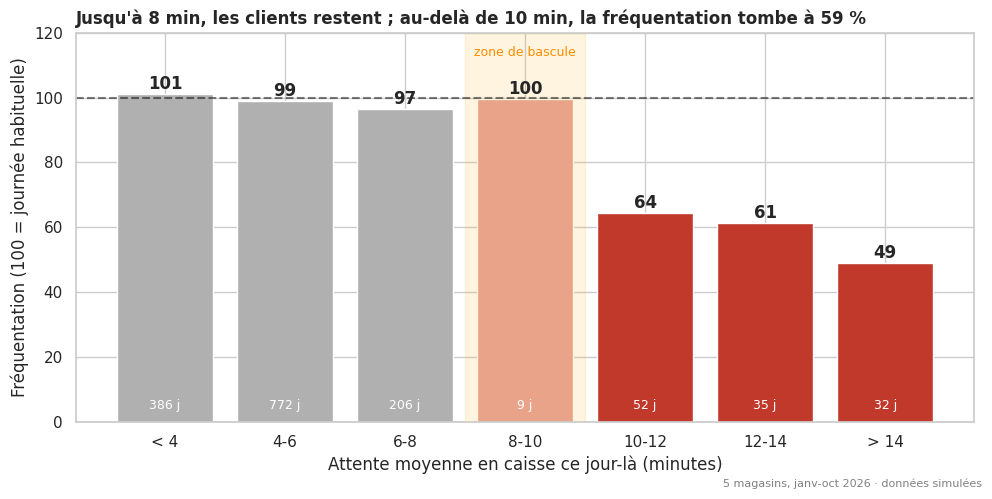

In [48]:
fig, ax = plt.subplots(figsize=(10, 5))
couleurs_t = [GRIS if e in ["< 4", "4-6", "6-8"] else ("#E6A39B" if e == "8-10" else ROUGE) for e in seuil["tranche_attente"]]
ax.bar(seuil["tranche_attente"].astype(str), seuil["indice_moyen"], color=couleurs_t)
for i, (v, n) in enumerate(zip(seuil["indice_moyen"], seuil["journees"])):
    ax.text(i, v + 1.5, f"{v:.0f}", ha="center", fontweight="bold")
    ax.text(i, 4, f"{n} j", ha="center", color="white", fontsize=9)
ax.axhline(100, color="black", linestyle="--", alpha=0.5)
ax.axvspan(2.5, 3.5, color="orange", alpha=0.12)
ax.text(3, 113, "zone de bascule", ha="center", color="darkorange", fontsize=9)
ax.set_ylim(0, 120)
ax.set_xlabel("Attente moyenne en caisse ce jour-là (minutes)")
ax.set_ylabel("Fréquentation (100 = journée habituelle)")
ax.set_title(f"Jusqu'à 8 min, les clients restent ; au-delà de 10 min, la fréquentation tombe à {ind_sur_10:.0f} %",
             fontweight="bold", loc="left")
fig.text(0.99, 0.01, "5 magasins, janv-oct 2026 · données simulées", ha="right", fontsize=8, color="grey")
plt.tight_layout()
fig.savefig(IMG + "question_personnelle.png", dpi=200, bbox_inches="tight")
plt.show()

➡️ **Réponse : le seuil de tolérance se situe entre 8 et 10 minutes.** Quand l'attente reste sous **8 min**, la fréquentation est normale (**99 %** du niveau habituel en moyenne). Au-delà de **10 min**, elle tombe à **59 %**, et à 49 % au-delà de 14 min. La tranche 8-10 min ne compte que 9 journées : le seuil exact reste à confirmer.

**Ce que ça change pour la recommandation** : l'objectif opérationnel à donner au directeur de Rabat est **« jamais plus de 8 minutes d'attente, y compris le vendredi et le samedi »**. Et **Casablanca** n'est pas en danger aujourd'hui (5,8 min en moyenne), mais c'est le magasin le plus proche du seuil : son pic d'août à **6,7 min** mérite une surveillance mensuelle.

---
## 📝 PARTIE 10 — Conclusions (pour le comité, le README et LinkedIn)

In [49]:
# Récapitulatif chiffré, recalculé automatiquement
recap = {
    "CA de Rabat juin → juillet": f"{chute_juillet:+.0f} %",
    "CA mensuel moyen juil-oct vs janv-juin (Rabat / autres)": f"{evol_rabat:+.0f} % / {evol_autres_moy:+.1f} %",
    "Tickets par mois à Rabat / panier moyen": f"{evol_tickets_rabat:+.0f} % / {evol_panier_rabat:+.1f} %",
    "Attente en caisse à Rabat": f"{att_rabat_avant:.1f} → {att_rabat_apres:.1f} min (r = {corr:.2f})",
    "Piliers de Rabat revenus en sept-oct (vs autres)": f"{ret_piliers_rabat:.0f} % (vs {ret_piliers_autres:.0f} %)",
    "Baisse des visites ven-sam / autres jours": f"{baisse_ven_sam:.0f} % / {baisse_semaine:.0f} %",
    "CA perdu juil-oct / marge perdue par mois": f"{dh(ca_perdu_total)} / {dh(marge_perdue_mois)}",
    "Économie salariale par mois (hypothèse RH)": f"{dh(economie_mois)} → coût réel × {ratio_cout:.1f}",
    "Meilleur scénario": f"{int(meilleur['caisses_rouvertes'])} caisses rouvertes → {dh(meilleur['gain_net_mois'])} net / mois",
    "Seuil d'attente (ma question)": f"≤ 8 min : {ind_sous_8:.0f} % · > 10 min : {ind_sur_10:.0f} %",
}
pd.Series(recap, name="Chiffre clé").to_frame()

,Chiffre clé
CA de Rabat juin → juillet,-43 %
CA mensuel moyen juil-oct vs janv-juin (Rabat / autres),-40 % / +2.1 %
Tickets par mois à Rabat / panier moyen,-40 % / -1.0 %
Attente en caisse à Rabat,4.4 → 12.8 min (r = -0.98)
Piliers de Rabat revenus en sept-oct (vs autres),44 % (vs 100 %)
Baisse des visites ven-sam / autres jours,-52 % / -35 %
CA perdu juil-oct / marge perdue par mois,469 404 DH / 24 644 DH
Économie salariale par mois (hypothèse RH),13 500 DH → coût réel × 1.8
Meilleur scénario,3 caisses rouvertes → 9 228 DH net / mois
Seuil d'attente (ma question),≤ 8 min : 99 % · > 10 min : 59 %


1. **Le constat** : oui, Rabat va mal. Son CA chute de **43 % en juillet** et reste **40 % sous son niveau** de janvier-juin, alors que les 4 autres magasins sont stables (+2 % en moyenne). Ce sont les visites qui baissent (−40 %), pas le panier moyen (−1 %).
2. **La cause** : l'**attente en caisse** à Rabat passe de **4,4 à 12,8 minutes** dès juillet, uniquement dans ce magasin (corrélation −0,98 avec le nombre de tickets).
3. **Les fausses pistes écartées** : l'été (autres magasins +2 %), la hausse des prix de mai (Rabat vendait encore bien en mai-juin), des paniers plus petits (−1 %), une fermeture (ouvert tous les jours).
4. **Qui et quand** : les **meilleurs clients** : seuls **44 % des Piliers** de Rabat sont revenus (100 % ailleurs). Le problème est le pire le **vendredi et le samedi** (−52 % de visites, 15 min d'attente).
5. **Le coût** : **469 000 DH de CA** perdus en 4 mois, soit **≈ 24 600 DH de marge par mois**, pour une économie de salaires de 13 500 DH par mois *(hypothèse à confirmer)* : l'économie coûte 1,8 fois ce qu'elle rapporte.
6. **La recommandation et son gain** : **rouvrir les 3 caisses** à Rabat (gain net estimé ≈ **+9 200 DH par mois**), avec un objectif d'attente **≤ 8 minutes**, une priorité sur le vendredi-samedi, et une **campagne de relance des 158 clients fidèles** absents depuis le 1er septembre, en commençant par les 33 Piliers.
7. **Ma question personnelle** : les clients décrochent au-delà de **8 à 10 minutes** d'attente (fréquentation 99 % sous 8 min, 59 % au-delà de 10 min). Casablanca (6,7 min en août) est le prochain magasin à surveiller.
8. **Ce que j'ai appris** : vérifier chaque fichier avant de calculer (150 doublons et 519 noms mal saisis auraient faussé tout le constat) ; comparer systématiquement à un groupe témoin (les autres magasins) ; une corrélation ne prouve rien seule, c'est la **concordance** (date, lieu, mécanisme, suspects écartés) qui prouve ; et un chiffre parle au comité quand il est traduit en dirhams.

---
## ⭐ BONUS — La liste des clients à relancer
Un client fidèle qui n'est pas venu depuis le **1er septembre 2026** est **à risque**. Combien par magasin ? On enregistre la liste de Rabat, avec le segment, pour le service marketing.

In [50]:
derniere = fideles.groupby(["client_id", "magasin"]).agg(
    derniere_visite=("date", "max"), visites_total=("ticket_id", "count")).reset_index()
derniere = derniere.merge(profil[["client_id", "segment", "visites", "montant"]], on="client_id", how="left")
derniere["segment"] = derniere["segment"].fillna("Nouveau (1re visite après juin)")
derniere = derniere.merge(clients[["client_id", "tranche_age", "date_inscription"]], on="client_id", how="left")

a_risque = derniere[derniere["derniere_visite"] < "2026-09-01"]
par_magasin = pd.DataFrame({
    "clients_fideles": derniere.groupby("magasin").size(),
    "a_risque": a_risque.groupby("magasin").size(),
})
par_magasin["part_%"] = par_magasin["a_risque"] / par_magasin["clients_fideles"] * 100
display(par_magasin.sort_values("part_%", ascending=False).round(1))

priorite = {"Piliers": 1, "Réguliers": 2, "Occasionnels": 3}
relance = (a_risque[a_risque["magasin"] == "Rabat"]
           .assign(priorite=lambda d: d["segment"].map(priorite).fillna(4).astype(int))
           .rename(columns={"visites": "visites_janv_juin", "montant": "montant_janv_juin_dh"})
           .sort_values(["priorite", "montant_janv_juin_dh"], ascending=[True, False])
           [["client_id", "segment", "priorite", "tranche_age", "derniere_visite",
             "visites_janv_juin", "montant_janv_juin_dh"]])
relance["derniere_visite"] = relance["derniere_visite"].dt.date
relance.to_csv("clients_a_relancer_rabat.csv", index=False, encoding="utf-8-sig")
nb_relance = len(relance)
print(f"{nb_relance} clients de Rabat à relancer, dont :")
print(relance["segment"].value_counts())
relance.head(10)

,clients_fideles,a_risque,part_%
magasin,,,
Rabat,419,158,37.70
Casablanca,516,78,15.10
Tanger,259,34,13.10
Agadir,230,26,11.30
Marrakech,319,34,10.70


158 clients de Rabat à relancer, dont :
segment
Occasionnels                       81
Réguliers                          43
Piliers                            33
Nouveau (1re visite après juin)     1
Name: count, dtype: int64


,client_id,segment,priorite,tranche_age,derniere_visite,visites_janv_juin,montant_janv_juin_dh
582,C0587,Piliers,1,Inconnue,2026-06-27,38.00,"13,963.18"
877,C0883,Piliers,1,36-45,2026-06-23,41.00,"12,280.02"
679,C0684,Piliers,1,26-35,2026-06-22,38.00,"11,273.26"
763,C0768,Piliers,1,26-35,2026-06-24,31.00,"10,882.77"
540,C0545,Piliers,1,36-45,2026-06-27,27.00,"9,990.72"
713,C0718,Piliers,1,26-35,2026-06-26,27.00,"9,627.72"
720,C0725,Piliers,1,18-25,2026-06-30,27.00,"8,851.70"
922,C0928,Piliers,1,26-35,2026-06-26,24.00,"8,160.08"
637,C0642,Piliers,1,26-35,2026-06-28,26.00,"8,077.93"
542,C0547,Piliers,1,18-25,2026-06-23,22.00,"7,269.08"


➡️ **158 clients fidèles de Rabat** (38 % de sa clientèle fidèle) ne sont pas venus depuis le 1er septembre, contre 11 à 15 % dans les autres magasins. La liste est enregistrée dans `clients_a_relancer_rabat.csv`, triée par priorité : **33 Piliers d'abord** (ils dépensaient jusqu'à 14 000 DH en 6 mois), puis 43 Réguliers et 81 Occasionnels. Fait parlant : les Piliers perdus ont presque tous fait leur dernière visite **fin juin**, juste avant l'allongement de l'attente.

---
## 📥 Récupérer les résultats (Google Colab)
Télécharge sur ton ordinateur le tableau de bord, le graphique de ta question personnelle et la liste des clients à relancer, pour les mettre dans ton dépôt GitHub.

In [53]:
try:
    from google.colab import files
    for chemin in [IMG + "tableau_de_bord.png", IMG + "question_personnelle.png", "clients_a_relancer_rabat.csv"]:
        files.download(chemin)
except ImportError:
    print("Hors de Colab : les fichiers sont déjà dans images/ et à la racine du projet.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>